In [1]:
import os
import torch
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from collections import Counter
BASE = "/kaggle/input/datasets/bhoomi0805/segmentation-data/plantseg"
print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
print("\nDataset exists:", os.path.exists(BASE))
for split in ["train", "val", "test"]:
    image_dir = os.path.join(BASE, "images", split)
    mask_dir = os.path.join(BASE, "annotations", split)
    print(f"\n{split.upper()}")
    print("Images folder exists:", os.path.exists(image_dir))
    print("Masks folder exists:", os.path.exists(mask_dir))


PyTorch: 2.11.0+cu130
CUDA available: True
GPU: Tesla T4

Dataset exists: True

TRAIN
Images folder exists: True
Masks folder exists: True

VAL
Images folder exists: True
Masks folder exists: True

TEST
Images folder exists: True
Masks folder exists: True


In [2]:

splits = ["train", "val", "test"]

tomato_data = {}

for split in splits:

    image_dir = os.path.join(BASE, "images", split)
    mask_dir = os.path.join(BASE, "annotations", split)

    image_files = [
        f for f in os.listdir(image_dir)
        if f.lower().startswith("tomato")
        and f.lower().endswith((".jpg", ".jpeg", ".png"))
    ]

    mask_files = [
        f for f in os.listdir(mask_dir)
        if f.lower().startswith("tomato")
        and f.lower().endswith(".png")
    ]

    image_map = {
        os.path.splitext(f)[0]: f for f in image_files
    }

    mask_map = {
        os.path.splitext(f)[0]: f for f in mask_files
    }

    matched_names = sorted(set(image_map) & set(mask_map))

    tomato_data[split] = [
        (
            os.path.join(image_dir, image_map[name]),
            os.path.join(mask_dir, mask_map[name])
        )
        for name in matched_names
    ]

    print(f"\n{split.upper()}")
    print("Tomato images:", len(image_files))
    print("Tomato masks:", len(mask_files))
    print("Matched image-mask pairs:", len(matched_names))
    print("Images without masks:", len(set(image_map) - set(mask_map)))
    print("Masks without images:", len(set(mask_map) - set(image_map)))

print("\nTOTAL MATCHED PAIRS:",
      sum(len(tomato_data[s]) for s in splits))



TRAIN
Tomato images: 460
Tomato masks: 460
Matched image-mask pairs: 460
Images without masks: 0
Masks without images: 0

VAL
Tomato images: 74
Tomato masks: 74
Matched image-mask pairs: 74
Images without masks: 0
Masks without images: 0

TEST
Tomato images: 133
Tomato masks: 133
Matched image-mask pairs: 133
Images without masks: 0
Masks without images: 0

TOTAL MATCHED PAIRS: 667


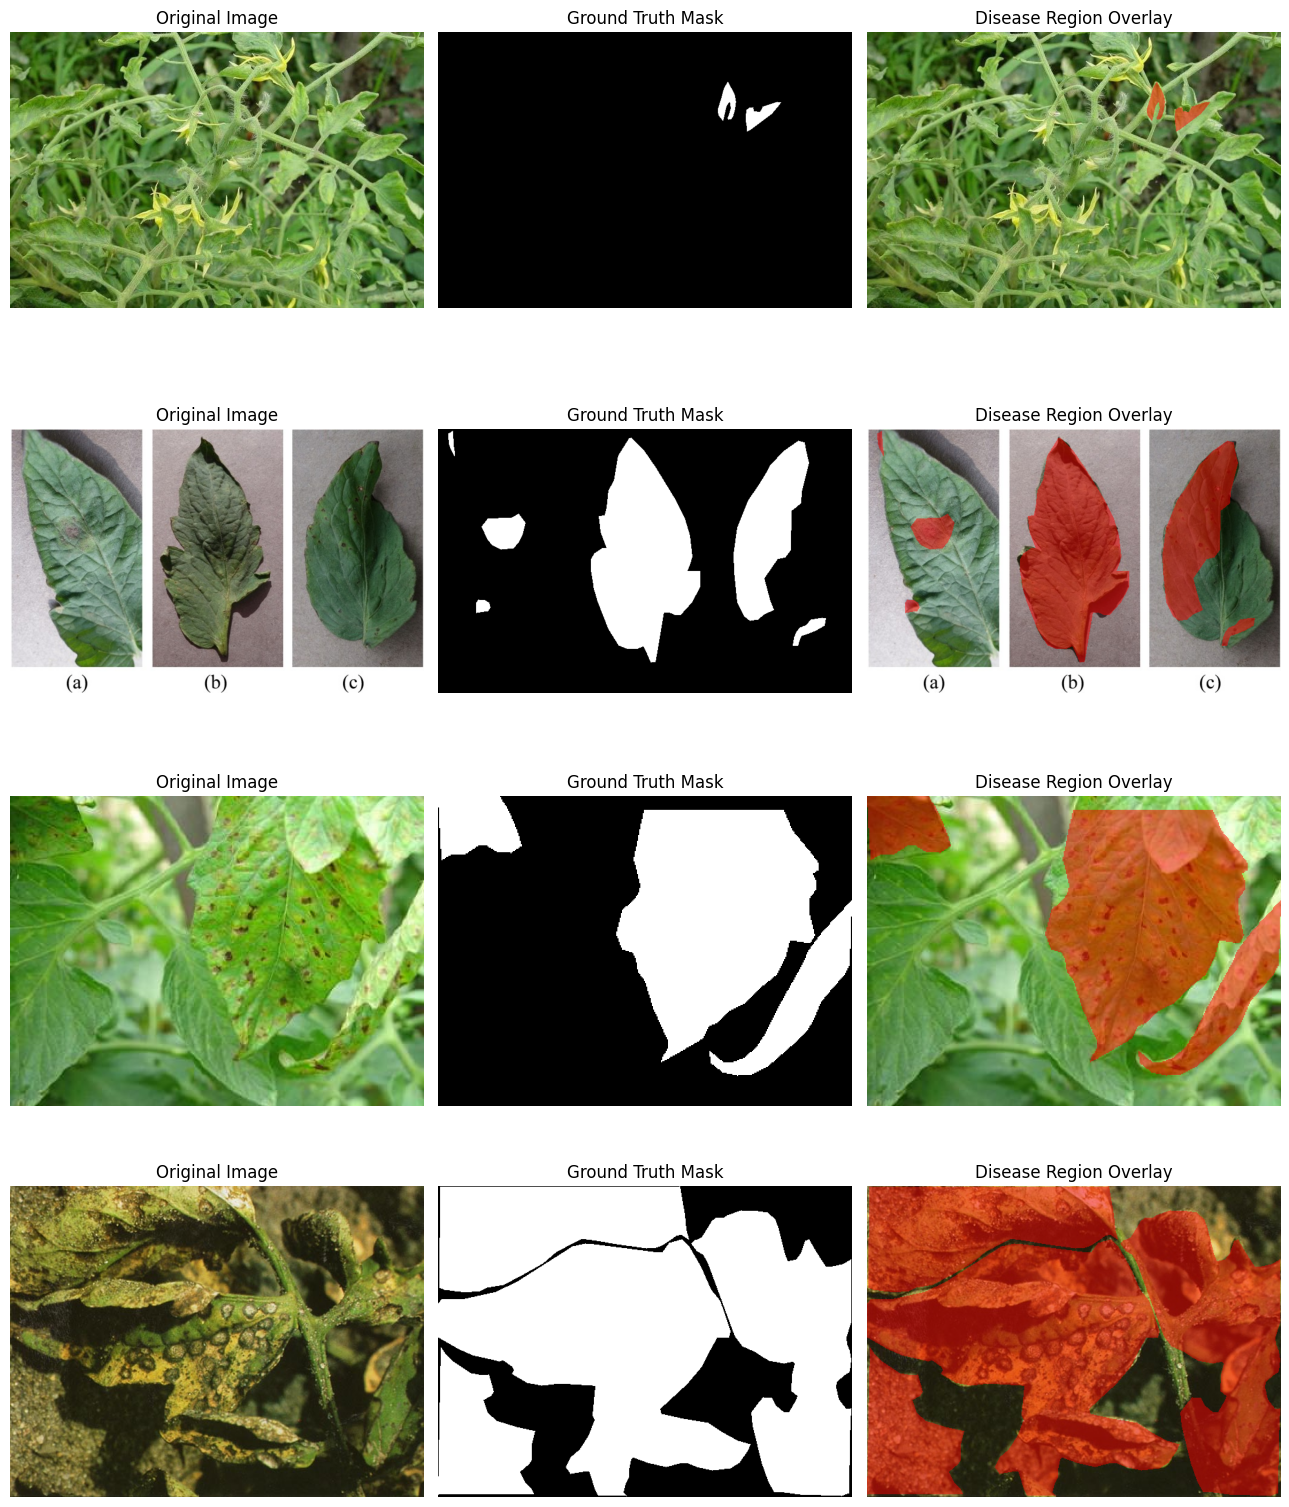

In [3]:

import random
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

random.seed(42)

samples = random.sample(tomato_data["train"], 4)

fig, axes = plt.subplots(4, 3, figsize=(13, 16))

for i, (image_path, mask_path) in enumerate(samples):

    image = np.array(Image.open(image_path).convert("RGB"))
    mask = np.array(Image.open(mask_path).convert("L"))

    binary_mask = mask > 0

    overlay = image.copy()
    overlay[binary_mask] = (
        0.5 * overlay[binary_mask]
        + 0.5 * np.array([255, 0, 0])
    ).astype(np.uint8)

    axes[i, 0].imshow(image)
    axes[i, 0].set_title("Original Image")

    axes[i, 1].imshow(binary_mask, cmap="gray")
    axes[i, 1].set_title("Ground Truth Mask")

    axes[i, 2].imshow(overlay)
    axes[i, 2].set_title("Disease Region Overlay")

    for j in range(3):
        axes[i, j].axis("off")

plt.tight_layout()
plt.show()


In [4]:

for split in ["train", "val", "test"]:

    ratios = []
    empty_masks = 0

    for image_path, mask_path in tomato_data[split]:

        mask = np.array(
            Image.open(mask_path).convert("L")
        )

        binary_mask = mask > 0

        positive_pixels = np.sum(binary_mask)
        total_pixels = binary_mask.size

        ratio = (positive_pixels / total_pixels) * 100
        ratios.append(ratio)

        if positive_pixels == 0:
            empty_masks += 1

    print(f"\n{split.upper()} MASK STATISTICS")
    print("Total masks:", len(ratios))
    print("Empty masks:", empty_masks)
    print("Minimum disease area (%):", round(min(ratios), 3))
    print("Maximum disease area (%):", round(max(ratios), 3))
    print("Average disease area (%):", round(np.mean(ratios), 3))
    print("Median disease area (%):", round(np.median(ratios), 3))



TRAIN MASK STATISTICS
Total masks: 460
Empty masks: 0
Minimum disease area (%): 0.629
Maximum disease area (%): 78.09
Average disease area (%): 17.253
Median disease area (%): 12.759

VAL MASK STATISTICS
Total masks: 74
Empty masks: 0
Minimum disease area (%): 1.364
Maximum disease area (%): 80.304
Average disease area (%): 16.623
Median disease area (%): 13.462

TEST MASK STATISTICS
Total masks: 133
Empty masks: 0
Minimum disease area (%): 0.572
Maximum disease area (%): 79.238
Average disease area (%): 18.727
Median disease area (%): 14.346


In [5]:

for split in ["train", "val", "test"]:

    image_sizes = Counter()
    mask_sizes = Counter()

    for image_path, mask_path in tomato_data[split]:

        with Image.open(image_path) as img:
            image_sizes[img.size] += 1

        with Image.open(mask_path) as mask:
            mask_sizes[mask.size] += 1

    print(f"\n{split.upper()}")
    print("Image dimensions:")
    for size, count in image_sizes.most_common(10):
        print(size, ":", count)

    print("Mask dimensions:")
    for size, count in mask_sizes.most_common(10):
        print(size, ":", count)



TRAIN
Image dimensions:
(640, 480) : 12
(1200, 1600) : 12
(690, 518) : 10
(600, 380) : 6
(800, 533) : 6
(640, 853) : 5
(600, 400) : 5
(1024, 768) : 5
(400, 300) : 5
(660, 521) : 5
Mask dimensions:
(640, 480) : 12
(1200, 1600) : 12
(690, 518) : 10
(600, 380) : 6
(800, 533) : 6
(640, 853) : 5
(600, 400) : 5
(1024, 768) : 5
(400, 300) : 5
(660, 521) : 5

VAL
Image dimensions:
(800, 1200) : 2
(720, 1280) : 2
(1200, 1600) : 2
(556, 316) : 1
(232, 138) : 1
(620, 465) : 1
(638, 411) : 1
(777, 1381) : 1
(640, 640) : 1
(650, 650) : 1
Mask dimensions:
(800, 1200) : 2
(720, 1280) : 2
(1200, 1600) : 2
(556, 316) : 1
(232, 138) : 1
(620, 465) : 1
(638, 411) : 1
(777, 1381) : 1
(640, 640) : 1
(650, 650) : 1

TEST
Image dimensions:
(600, 380) : 5
(400, 300) : 3
(640, 480) : 3
(690, 518) : 3
(450, 600) : 3
(600, 400) : 2
(660, 495) : 2
(620, 410) : 2
(1280, 879) : 2
(300, 225) : 2
Mask dimensions:
(600, 380) : 5
(600, 450) : 4
(400, 300) : 3
(640, 480) : 3
(690, 518) : 3
(600, 400) : 2
(660, 495) : 2

In [6]:

for split in ["train", "val", "test"]:

    mismatches = []
    image_modes = Counter()
    mask_modes = Counter()
    image_dimensions = []

    for image_path, mask_path in tomato_data[split]:

        with Image.open(image_path) as img:
            image_size = img.size
            image_modes[img.mode] += 1

        with Image.open(mask_path) as mask:
            mask_size = mask.size
            mask_modes[mask.mode] += 1

        image_dimensions.append(image_size)

        if image_size != mask_size:
            mismatches.append(
                (os.path.basename(image_path), image_size, mask_size)
            )

    print(f"\n{split.upper()}")
    print("Total pairs:", len(tomato_data[split]))
    print("Dimension mismatches:", len(mismatches))
    print("Image modes:", image_modes)
    print("Mask modes:", mask_modes)
    print("Smallest image dimensions:",
          min(image_dimensions, key=lambda x: x[0] * x[1]))
    print("Largest image dimensions:",
          max(image_dimensions, key=lambda x: x[0] * x[1]))

    if mismatches:
        print("Mismatch examples:", mismatches[:5])

print("\nDIMENSION VERIFICATION COMPLETE")



TRAIN
Total pairs: 460
Dimension mismatches: 2
Image modes: Counter({'RGB': 460})
Mask modes: Counter({'L': 460})
Smallest image dimensions: (126, 168)
Largest image dimensions: (3680, 5408)
Mismatch examples: [('tomato_bacterial_leaf_spot_42.jpg', (438, 364), (364, 438)), ('tomato_early_blight_google_0043.jpg', (600, 450), (450, 600))]

VAL
Total pairs: 74
Dimension mismatches: 0
Image modes: Counter({'RGB': 74})
Mask modes: Counter({'L': 74})
Smallest image dimensions: (232, 138)
Largest image dimensions: (3648, 2736)

TEST
Total pairs: 133
Dimension mismatches: 3
Image modes: Counter({'RGB': 133})
Mask modes: Counter({'L': 133})
Smallest image dimensions: (200, 149)
Largest image dimensions: (1920, 1440)
Mismatch examples: [('tomato_early_blight_google_0000.jpg', (450, 600), (600, 450)), ('tomato_early_blight_google_0056.jpg', (450, 600), (600, 450)), ('tomato_septoria_leaf_spot_google_0033.jpg', (450, 600), (600, 450))]

DIMENSION VERIFICATION COMPLETE


tomato_bacterial_leaf_spot_42.jpg | EXIF orientation: 6 | Image: (438, 364) | Corrected: (364, 438) | Mask: (364, 438)
tomato_early_blight_google_0043.jpg | EXIF orientation: 6 | Image: (600, 450) | Corrected: (450, 600) | Mask: (450, 600)
tomato_early_blight_google_0000.jpg | EXIF orientation: 6 | Image: (450, 600) | Corrected: (600, 450) | Mask: (600, 450)
tomato_early_blight_google_0056.jpg | EXIF orientation: 6 | Image: (450, 600) | Corrected: (600, 450) | Mask: (600, 450)
tomato_septoria_leaf_spot_google_0033.jpg | EXIF orientation: 6 | Image: (450, 600) | Corrected: (600, 450) | Mask: (600, 450)


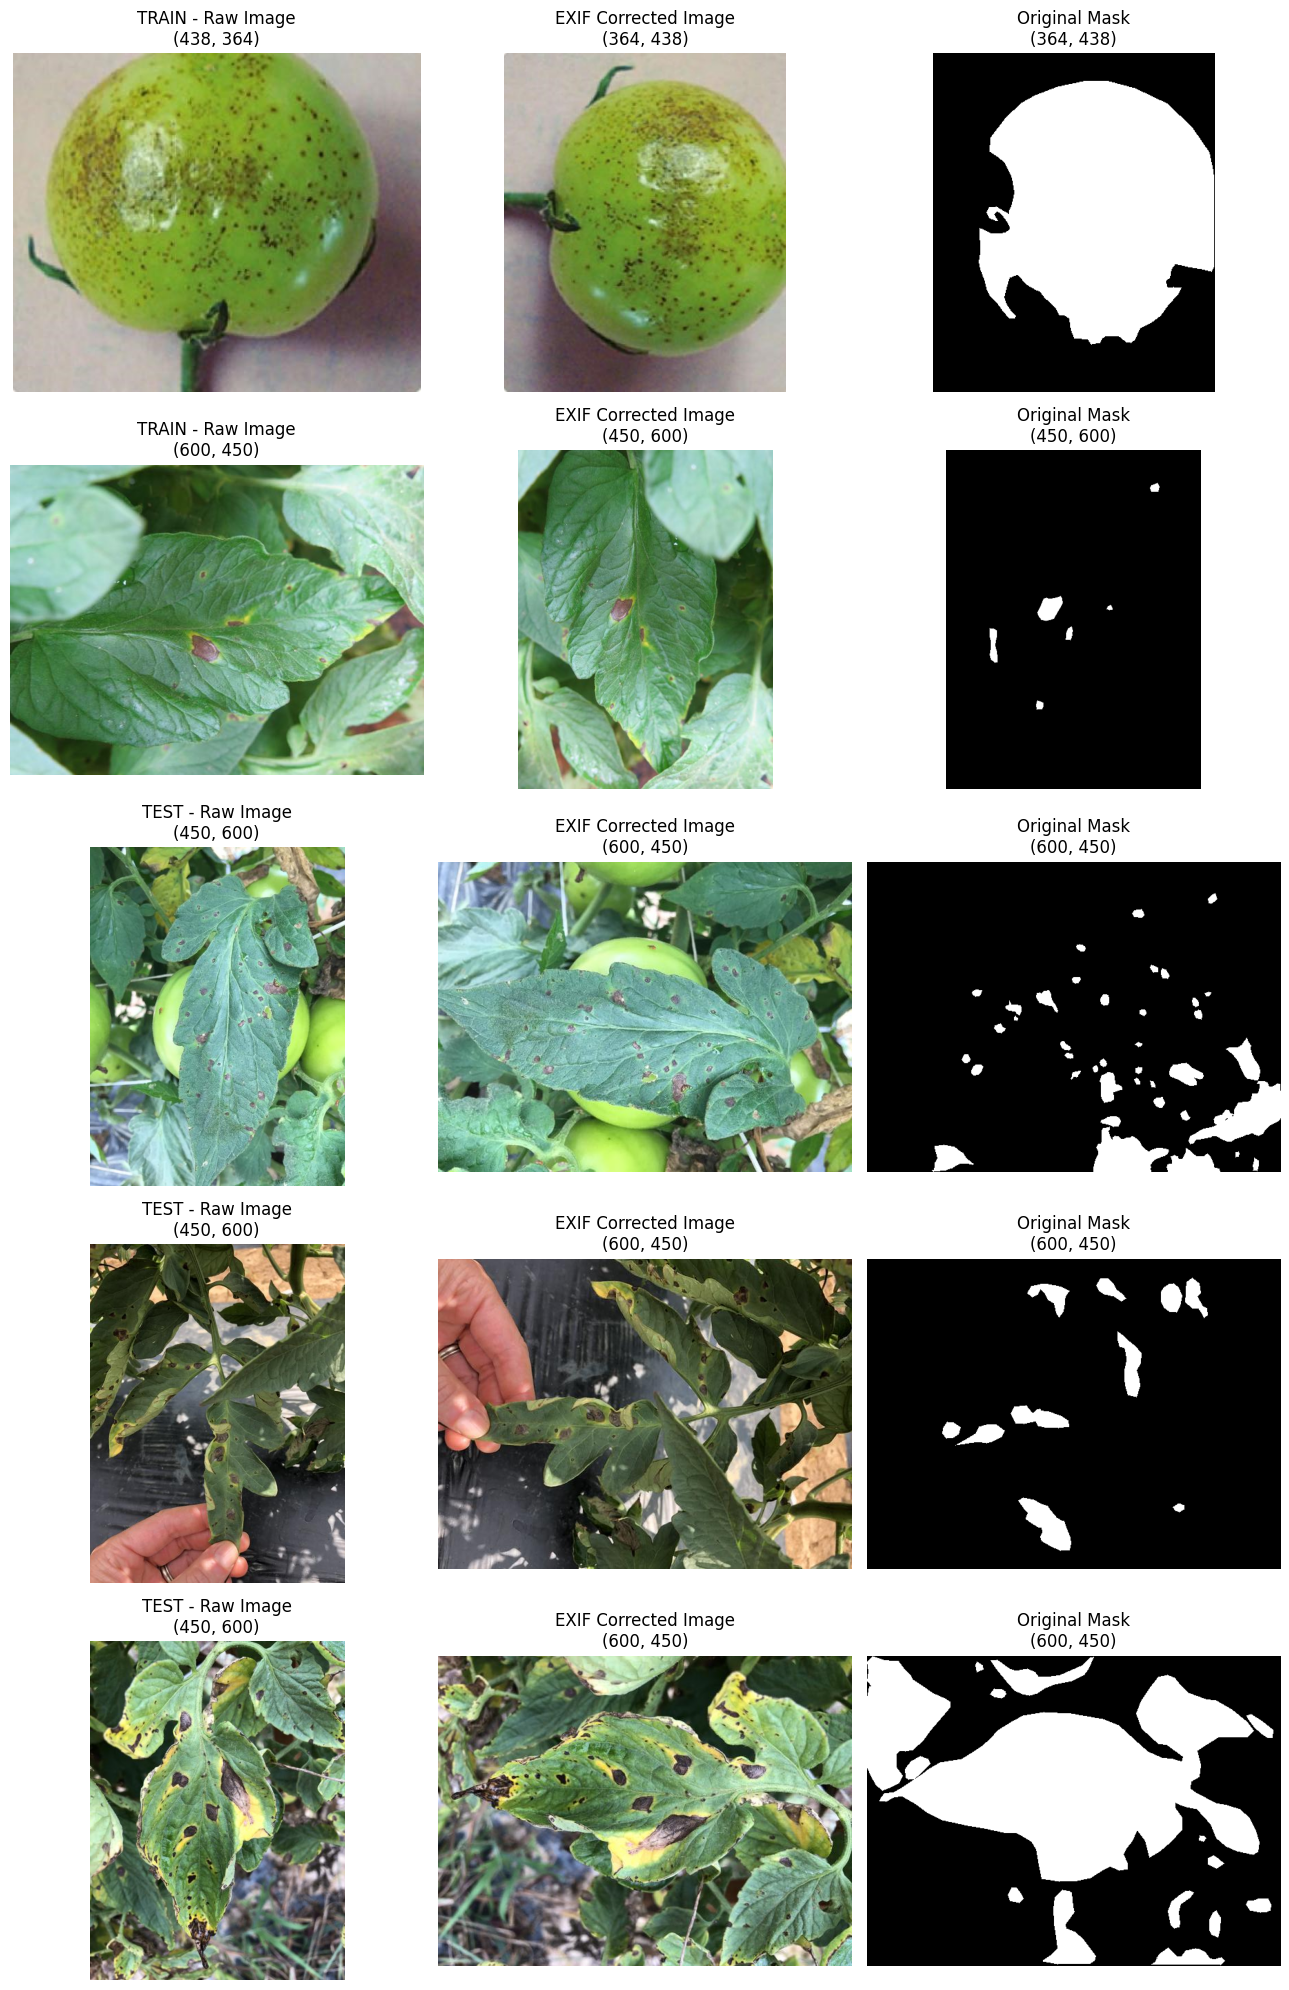

In [7]:

from PIL import Image, ImageOps
import matplotlib.pyplot as plt
import os

mismatch_pairs = []

for split in ["train", "val", "test"]:
    for image_path, mask_path in tomato_data[split]:

        with Image.open(image_path) as img, Image.open(mask_path) as mask:
            if img.size != mask.size:
                mismatch_pairs.append(
                    (split, image_path, mask_path)
                )

fig, axes = plt.subplots(
    len(mismatch_pairs), 3,
    figsize=(13, 4 * len(mismatch_pairs))
)

for i, (split, image_path, mask_path) in enumerate(mismatch_pairs):

    with Image.open(image_path) as img:
        raw_image = img.convert("RGB")
        corrected_image = ImageOps.exif_transpose(img).convert("RGB")

        orientation = img.getexif().get(274, "Not set")

    with Image.open(mask_path) as mask:
        mask = mask.convert("L")

    axes[i, 0].imshow(raw_image)
    axes[i, 0].set_title(
        f"{split.upper()} - Raw Image\n{raw_image.size}"
    )

    axes[i, 1].imshow(corrected_image)
    axes[i, 1].set_title(
        f"EXIF Corrected Image\n{corrected_image.size}"
    )

    axes[i, 2].imshow(mask, cmap="gray")
    axes[i, 2].set_title(
        f"Original Mask\n{mask.size}"
    )

    print(
        os.path.basename(image_path),
        "| EXIF orientation:", orientation,
        "| Image:", raw_image.size,
        "| Corrected:", corrected_image.size,
        "| Mask:", mask.size
    )

    for j in range(3):
        axes[i, j].axis("off")

plt.tight_layout()
plt.show()


In [8]:

from PIL import Image, ImageOps

orientation_mismatches = []

for split in ["train", "val", "test"]:

    corrected_count = 0
    remaining_mismatches = []

    for image_path, mask_path in tomato_data[split]:

        with Image.open(image_path) as img:
            corrected_image = ImageOps.exif_transpose(img)

            with Image.open(mask_path) as mask:
                if corrected_image.size != mask.size:
                    remaining_mismatches.append(
                        os.path.basename(image_path)
                    )

            if img.size != corrected_image.size:
                corrected_count += 1

    print(f"\n{split.upper()}")
    print("EXIF orientation corrections:", corrected_count)
    print("Remaining dimension mismatches:",
          len(remaining_mismatches))

    if remaining_mismatches:
        print(remaining_mismatches)

print("\nORIENTATION AUDIT COMPLETED")



TRAIN
EXIF orientation corrections: 2
Remaining dimension mismatches: 0

VAL
EXIF orientation corrections: 0
Remaining dimension mismatches: 0

TEST
EXIF orientation corrections: 3
Remaining dimension mismatches: 0

ORIENTATION AUDIT COMPLETED


In [9]:

import torch
import numpy as np
from PIL import Image, ImageOps
from torch.utils.data import Dataset, DataLoader

SEG_SIZE = 512

class TomatoSegmentationDataset(Dataset):

    def __init__(self, samples, augment=False):
        self.samples = samples
        self.augment = augment

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):

        image_path, mask_path = self.samples[idx]

        image = ImageOps.exif_transpose(
            Image.open(image_path)
        ).convert("RGB")

        mask = Image.open(mask_path).convert("L")

        if image.size != mask.size:
            raise ValueError(
                f"Image-mask mismatch: {image_path}"
            )

        width, height = image.size

        scale = min(
            SEG_SIZE / width,
            SEG_SIZE / height
        )

        new_width = max(1, round(width * scale))
        new_height = max(1, round(height * scale))

        image = image.resize(
            (new_width, new_height),
            Image.Resampling.BILINEAR
        )

        mask = mask.resize(
            (new_width, new_height),
            Image.Resampling.NEAREST
        )

        image_canvas = Image.new(
            "RGB", (SEG_SIZE, SEG_SIZE), (0, 0, 0)
        )

        mask_canvas = Image.new(
            "L", (SEG_SIZE, SEG_SIZE), 0
        )

        left = (SEG_SIZE - new_width) // 2
        top = (SEG_SIZE - new_height) // 2

        image_canvas.paste(image, (left, top))
        mask_canvas.paste(mask, (left, top))

        image_array = np.asarray(
            image_canvas, dtype=np.float32
        ) / 255.0

        mask_array = (
            np.asarray(mask_canvas, dtype=np.uint8) > 0
        ).astype(np.float32)

        image_tensor = torch.from_numpy(
            image_array.transpose(2, 0, 1).copy()
        )

        mask_tensor = torch.from_numpy(
            mask_array[None, :, :].copy()
        )

        return image_tensor, mask_tensor


train_dataset = TomatoSegmentationDataset(
    tomato_data["train"], augment=False
)

val_dataset = TomatoSegmentationDataset(
    tomato_data["val"], augment=False
)

test_dataset = TomatoSegmentationDataset(
    tomato_data["test"], augment=False
)

print("512x512 datasets created successfully!")
print("Train:", len(train_dataset))
print("Validation:", len(val_dataset))
print("Test:", len(test_dataset))

x, y = train_dataset[0]

print("\nImage shape:", x.shape)
print("Mask shape:", y.shape)
print("Image range:", x.min().item(), "to", x.max().item())
print("Mask values:", torch.unique(y))


512x512 datasets created successfully!
Train: 460
Validation: 74
Test: 133

Image shape: torch.Size([3, 512, 512])
Mask shape: torch.Size([1, 512, 512])
Image range: 0.0 to 0.9686274528503418
Mask values: tensor([0., 1.])


In [10]:

from torch.utils.data import DataLoader

BATCH_SIZE = 4

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=True,
    drop_last=False
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

print("DataLoaders created successfully!")
print("Train batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Test batches:", len(test_loader))

images, masks = next(iter(train_loader))

print("\nBatch image shape:", images.shape)
print("Batch mask shape:", masks.shape)
print("GPU:", torch.cuda.get_device_name(0))


DataLoaders created successfully!
Train batches: 115
Validation batches: 19
Test batches: 34

Batch image shape: torch.Size([4, 3, 512, 512])
Batch mask shape: torch.Size([4, 1, 512, 512])
GPU: Tesla T4


In [11]:

import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision.models import resnet18, ResNet18_Weights

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")


class ConvBlock(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()

        self.block = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),

            nn.Conv2d(out_channels, out_channels, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        return self.block(x)


class DecoderBlock(nn.Module):
    def __init__(self, in_channels, skip_channels, out_channels):
        super().__init__()

        self.conv = ConvBlock(
            in_channels + skip_channels,
            out_channels
        )

    def forward(self, x, skip):
        x = F.interpolate(
            x,
            size=skip.shape[-2:],
            mode="bilinear",
            align_corners=False
        )

        x = torch.cat([x, skip], dim=1)

        return self.conv(x)


class ResNet18UNet(nn.Module):
    def __init__(self, pretrained=True):
        super().__init__()

        weights = (
            ResNet18_Weights.DEFAULT if pretrained else None
        )

        encoder = resnet18(weights=weights)

        self.conv1 = encoder.conv1
        self.bn1 = encoder.bn1
        self.relu = encoder.relu
        self.maxpool = encoder.maxpool

        self.layer1 = encoder.layer1
        self.layer2 = encoder.layer2
        self.layer3 = encoder.layer3
        self.layer4 = encoder.layer4

        self.decoder3 = DecoderBlock(512, 256, 256)
        self.decoder2 = DecoderBlock(256, 128, 128)
        self.decoder1 = DecoderBlock(128, 64, 64)
        self.decoder0 = DecoderBlock(64, 64, 64)

        self.final_conv = nn.Sequential(
            nn.Conv2d(64, 32, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
            nn.Conv2d(32, 1, kernel_size=1)
        )

        self.register_buffer(
            "mean",
            torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1)
        )

        self.register_buffer(
            "std",
            torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1)
        )

    def forward(self, x):

        input_size = x.shape[-2:]

        x = (x - self.mean) / self.std

        x0 = self.relu(self.bn1(self.conv1(x)))
        x1 = self.layer1(self.maxpool(x0))
        x2 = self.layer2(x1)
        x3 = self.layer3(x2)
        x4 = self.layer4(x3)

        x = self.decoder3(x4, x3)
        x = self.decoder2(x, x2)
        x = self.decoder1(x, x1)
        x = self.decoder0(x, x0)

        x = F.interpolate(
            x,
            size=input_size,
            mode="bilinear",
            align_corners=False
        )

        return self.final_conv(x)


# Initialize model with ImageNet pretrained weights
seg_model = ResNet18UNet(pretrained=True).to(device)

print("Model initialized successfully!")
print("Architecture: U-Net with ResNet18 encoder")
print("Pretrained encoder: ImageNet")
print("Device:", device)

total_params = sum(
    p.numel() for p in seg_model.parameters()
)

trainable_params = sum(
    p.numel() for p in seg_model.parameters()
    if p.requires_grad
)

print("Total parameters:", f"{total_params:,}")
print("Trainable parameters:", f"{trainable_params:,}")

# Small forward-pass verification
seg_model.eval()

with torch.no_grad():
    sample = torch.randn(1, 3, 512, 512, device=device)
    output = seg_model(sample)

print("Test input shape:", sample.shape)
print("Model output shape:", output.shape)

assert output.shape == (1, 1, 512, 512)

print("\n512x512 segmentation model verified!")


Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 165MB/s] 


Model initialized successfully!
Architecture: U-Net with ResNet18 encoder
Pretrained encoder: ImageNet
Device: cuda
Total parameters: 14,404,225
Trainable parameters: 14,404,225
Test input shape: torch.Size([1, 3, 512, 512])
Model output shape: torch.Size([1, 1, 512, 512])

512x512 segmentation model verified!


In [12]:

import time
import torch
import torch.nn as nn

# Combined BCE + Dice loss
bce_loss = nn.BCEWithLogitsLoss()

def dice_loss_fn(logits, targets, smooth=1.0):

    probabilities = torch.sigmoid(logits)

    probabilities = probabilities.flatten(1)
    targets = targets.flatten(1)

    intersection = (probabilities * targets).sum(dim=1)

    dice = (
        2.0 * intersection + smooth
    ) / (
        probabilities.sum(dim=1) + targets.sum(dim=1) + smooth
    )

    return 1.0 - dice.mean()


def combined_loss(logits, targets):

    loss_bce = bce_loss(logits, targets)
    loss_dice = dice_loss_fn(logits, targets)

    return 0.5 * loss_bce + 0.5 * loss_dice


optimizer = torch.optim.AdamW(
    seg_model.parameters(),
    lr=1e-4,
    weight_decay=1e-4
)

scaler = torch.amp.GradScaler("cuda")

# One real training batch to measure performance
seg_model.train()

images, masks = next(iter(train_loader))

images = images.to(device, non_blocking=True)
masks = masks.to(device, non_blocking=True)

torch.cuda.reset_peak_memory_stats()
torch.cuda.synchronize()

start_time = time.time()

optimizer.zero_grad(set_to_none=True)

with torch.autocast(
    device_type="cuda",
    dtype=torch.float16
):
    predictions = seg_model(images)
    loss = combined_loss(predictions, masks)

scaler.scale(loss).backward()
scaler.step(optimizer)
scaler.update()

torch.cuda.synchronize()

elapsed = time.time() - start_time

print("One-batch training test completed!")
print("Loss:", round(loss.item(), 4))
print("Batch size:", images.shape[0])
print("Time:", round(elapsed, 2), "seconds")
print(
    "Peak GPU memory:",
    round(torch.cuda.max_memory_allocated() / 1024**3, 2),
    "GB"
)
print("AMP enabled:", scaler.is_enabled())


One-batch training test completed!
Loss: 0.75
Batch size: 4
Time: 1.14 seconds
Peak GPU memory: 1.24 GB
AMP enabled: True


In [13]:

import os
import time
import copy
import torch

MAX_EPOCHS = 35
PATIENCE = 7

BEST_MODEL_PATH = (
    "/kaggle/working/best_segmentation_resnet18_unet_512.pth"
)

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="max",
    factor=0.5,
    patience=2
)

best_val_dice = 0.0
epochs_without_improvement = 0
history = []

training_start = time.time()

for epoch in range(MAX_EPOCHS):

    epoch_start = time.time()

    # TRAIN
    seg_model.train()
    train_loss_total = 0.0

    for images, masks in train_loader:

        images = images.to(device, non_blocking=True)
        masks = masks.to(device, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)

        with torch.autocast(
            device_type="cuda",
            dtype=torch.float16
        ):
            logits = seg_model(images)
            loss = combined_loss(logits, masks)

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        train_loss_total += loss.item()

    avg_train_loss = train_loss_total / len(train_loader)

    # VALIDATION
    seg_model.eval()
    val_loss_total = 0.0
    dice_total = 0.0

    with torch.inference_mode():

        for images, masks in val_loader:

            images = images.to(device, non_blocking=True)
            masks = masks.to(device, non_blocking=True)

            with torch.autocast(
                device_type="cuda",
                dtype=torch.float16
            ):
                logits = seg_model(images)
                loss = combined_loss(logits, masks)

            probabilities = torch.sigmoid(logits.float())
            predictions = (probabilities > 0.5).float()

            intersection = (predictions * masks).sum(
                dim=(1, 2, 3)
            )

            denominator = (
                predictions.sum(dim=(1, 2, 3))
                + masks.sum(dim=(1, 2, 3))
            )

            dice = (
                (2 * intersection + 1e-6)
                / (denominator + 1e-6)
            )

            val_loss_total += loss.item()
            dice_total += dice.mean().item()

    avg_val_loss = val_loss_total / len(val_loader)
    avg_val_dice = dice_total / len(val_loader)

    scheduler.step(avg_val_dice)

    # SAVE BEST CHECKPOINT
    improved = avg_val_dice > best_val_dice

    if improved:

        best_val_dice = avg_val_dice
        epochs_without_improvement = 0

        torch.save(
            {
                "epoch": epoch + 1,
                "model_state_dict": seg_model.state_dict(),
                "optimizer_state_dict": optimizer.state_dict(),
                "best_val_dice": best_val_dice,
                "resolution": 512
            },
            BEST_MODEL_PATH
        )

    else:
        epochs_without_improvement += 1

    epoch_time = time.time() - epoch_start

    history.append({
        "epoch": epoch + 1,
        "train_loss": avg_train_loss,
        "val_loss": avg_val_loss,
        "val_dice": avg_val_dice
    })

    print(
        f"Epoch {epoch+1}/{MAX_EPOCHS} | "
        f"Train Loss: {avg_train_loss:.4f} | "
        f"Val Loss: {avg_val_loss:.4f} | "
        f"Val Dice: {avg_val_dice:.4f} | "
        f"Time: {epoch_time/60:.2f} min | "
        f"{'BEST SAVED' if improved else 'No improvement'}"
    )

    if epochs_without_improvement >= PATIENCE:
        print("\nEarly stopping triggered.")
        break

total_time = (time.time() - training_start) / 60

print("\nTRAINING FINISHED")
print("Best validation Dice:", round(best_val_dice, 4))
print("Total training time:", round(total_time, 2), "minutes")
print("Checkpoint exists:", os.path.exists(BEST_MODEL_PATH))


Epoch 1/35 | Train Loss: 0.5152 | Val Loss: 0.3778 | Val Dice: 0.5724 | Time: 0.24 min | BEST SAVED
Epoch 2/35 | Train Loss: 0.3591 | Val Loss: 0.3437 | Val Dice: 0.6225 | Time: 0.24 min | BEST SAVED
Epoch 3/35 | Train Loss: 0.3253 | Val Loss: 0.3195 | Val Dice: 0.6431 | Time: 0.24 min | BEST SAVED
Epoch 4/35 | Train Loss: 0.2786 | Val Loss: 0.3247 | Val Dice: 0.6229 | Time: 0.24 min | No improvement
Epoch 5/35 | Train Loss: 0.2429 | Val Loss: 0.3211 | Val Dice: 0.6227 | Time: 0.24 min | No improvement
Epoch 6/35 | Train Loss: 0.2170 | Val Loss: 0.2920 | Val Dice: 0.6675 | Time: 0.24 min | BEST SAVED
Epoch 7/35 | Train Loss: 0.2130 | Val Loss: 0.3148 | Val Dice: 0.6580 | Time: 0.24 min | No improvement
Epoch 8/35 | Train Loss: 0.1831 | Val Loss: 0.2853 | Val Dice: 0.6744 | Time: 0.24 min | BEST SAVED
Epoch 9/35 | Train Loss: 0.1736 | Val Loss: 0.3347 | Val Dice: 0.6345 | Time: 0.24 min | No improvement
Epoch 10/35 | Train Loss: 0.1557 | Val Loss: 0.2929 | Val Dice: 0.6768 | Time: 0.24 

In [14]:

import torch
import numpy as np
import os

# Load best validation checkpoint
checkpoint = torch.load(
    BEST_MODEL_PATH,
    map_location=device,
    weights_only=False
)

seg_model.load_state_dict(checkpoint["model_state_dict"])
seg_model.eval()

print("Loaded best checkpoint from epoch:", checkpoint["epoch"])
print("Best validation Dice:", checkpoint["best_val_dice"])

# Test evaluation
all_dice = []
all_iou = []
total_tp = 0
total_fp = 0
total_fn = 0

with torch.inference_mode():

    for images, masks in test_loader:

        images = images.to(device, non_blocking=True)
        masks = masks.to(device, non_blocking=True)

        with torch.autocast(
            device_type="cuda",
            dtype=torch.float16
        ):
            logits = seg_model(images)

        predictions = (
            torch.sigmoid(logits.float()) > 0.5
        ).float()

        # Per-image metrics
        for pred, target in zip(predictions, masks):

            pred_flat = pred.flatten()
            target_flat = target.flatten()

            tp = (pred_flat * target_flat).sum()
            fp = (pred_flat * (1 - target_flat)).sum()
            fn = ((1 - pred_flat) * target_flat).sum()

            dice = (2 * tp + 1e-7) / (
                2 * tp + fp + fn + 1e-7
            )

            iou = (tp + 1e-7) / (
                tp + fp + fn + 1e-7
            )

            all_dice.append(dice.item())
            all_iou.append(iou.item())

            total_tp += tp.item()
            total_fp += fp.item()
            total_fn += fn.item()

# Macro-average across test images
macro_dice = float(np.mean(all_dice))
macro_iou = float(np.mean(all_iou))

# Global pixel-level metrics
global_dice = (
    2 * total_tp + 1e-7
) / (
    2 * total_tp + total_fp + total_fn + 1e-7
)

global_iou = (
    total_tp + 1e-7
) / (
    total_tp + total_fp + total_fn + 1e-7
)

precision = total_tp / (total_tp + total_fp + 1e-7)
recall = total_tp / (total_tp + total_fn + 1e-7)

print("\n========== FINAL TEST RESULTS ==========")
print("Test images:", len(all_dice))
print("Threshold: 0.50")
print("----------------------------------------")
print(f"Macro Dice:    {macro_dice:.4f}")
print(f"Macro IoU:     {macro_iou:.4f}")
print(f"Global Dice:   {global_dice:.4f}")
print(f"Global IoU:    {global_iou:.4f}")
print(f"Precision:     {precision:.4f}")
print(f"Recall:        {recall:.4f}")
print("----------------------------------------")
print("Checkpoint exists:", os.path.exists(BEST_MODEL_PATH))
print("========================================")


Loaded best checkpoint from epoch: 18
Best validation Dice: 0.6795100271701813

========== FINAL TEST RESULTS ==========
Test images: 133
Threshold: 0.50
----------------------------------------
Macro Dice:    0.6640
Macro IoU:     0.5283
Global Dice:   0.6955
Global IoU:    0.5332
Precision:     0.7556
Recall:        0.6442
----------------------------------------
Checkpoint exists: True


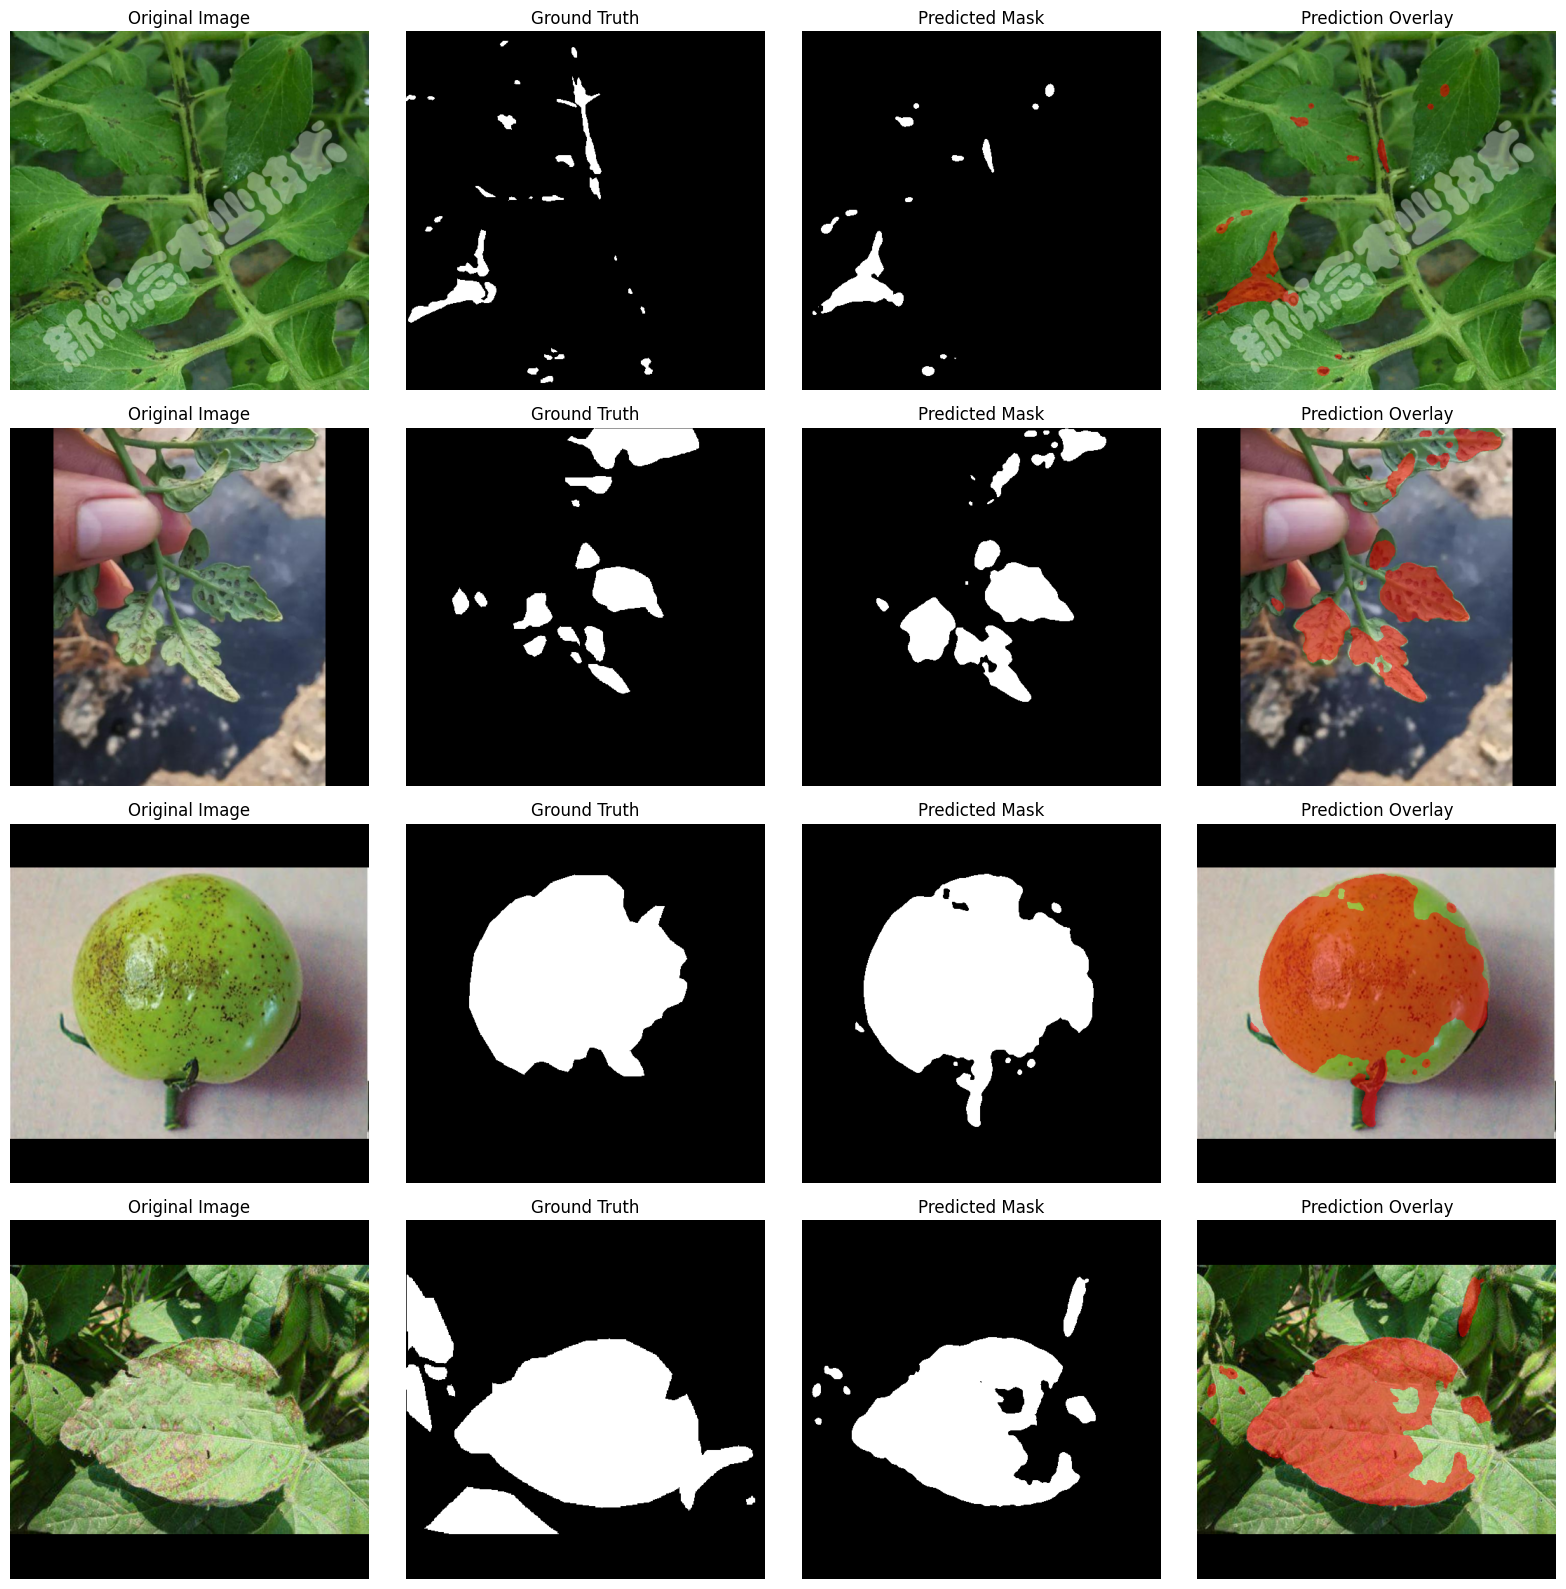

Prediction visualizations saved: /kaggle/working/segmentation_test_visuals.png
Checkpoint: /kaggle/working/best_segmentation_resnet18_unet_512.pth
Checkpoint size: 165.03 MB


In [15]:

import matplotlib.pyplot as plt
import numpy as np
import torch
import os

seg_model.eval()

num_samples = 4
fig, axes = plt.subplots(num_samples, 4, figsize=(16, 4 * num_samples))

for i in range(num_samples):

    image, mask = test_dataset[i]

    with torch.inference_mode():

        input_tensor = image.unsqueeze(0).to(device)

        with torch.autocast(
            device_type="cuda",
            dtype=torch.float16
        ):
            logits = seg_model(input_tensor)

        prediction = (
            torch.sigmoid(logits.float())[0, 0] > 0.5
        ).cpu().numpy()

    image_np = image.permute(1, 2, 0).numpy()
    mask_np = mask[0].numpy()

    overlay = (image_np * 255).astype(np.uint8).copy()

    overlay[prediction] = (
        0.5 * overlay[prediction]
        + 0.5 * np.array([255, 0, 0])
    ).astype(np.uint8)

    axes[i, 0].imshow(image_np)
    axes[i, 0].set_title("Original Image")

    axes[i, 1].imshow(mask_np, cmap="gray")
    axes[i, 1].set_title("Ground Truth")

    axes[i, 2].imshow(prediction, cmap="gray")
    axes[i, 2].set_title("Predicted Mask")

    axes[i, 3].imshow(overlay)
    axes[i, 3].set_title("Prediction Overlay")

    for ax in axes[i]:
        ax.axis("off")

plt.tight_layout()

visual_path = "/kaggle/working/segmentation_test_visuals.png"
plt.savefig(visual_path, dpi=150, bbox_inches="tight")
plt.show()

print("Prediction visualizations saved:", visual_path)
print("Checkpoint:", BEST_MODEL_PATH)
print("Checkpoint size:", round(os.path.getsize(BEST_MODEL_PATH) / (1024**2), 2), "MB")
